# Fil rouge ProtAnnotML · 3 — Les références à battre : alignement et décodage structuré

> **Objectif** : avant tout modèle profond, construire les **références** honnêtes. (1) Une méthode par **alignement** sur le répertoire de référence, dans l'esprit d'IMGT/DomainGapAlign : alignement, ancres, règles de longueur des CDR. (2) Un modèle **par résidu** très simple (régression logistique sur une fenêtre), rendu valide par un **décodage de Viterbi sous contraintes** (positions croissantes, régions ordonnées, étiquettes BIO cohérentes). On les compare sur les régimes du notebook 2 et sur des **tests de résistance**, et on en tire où un modèle appris peut réellement apporter quelque chose.

| | |
|---|---|
| **Durée estimée** | 2 h 30 |
| **Prérequis** | Fil rouge 1–2 ; modules 5 (alignement, attention), 10 (CRF, Viterbi) |
| **Librairies** | `numpy`, `scipy`, `scikit-learn`, `matplotlib` |

**Plan**

1. Ce que doit battre ProtAnnotML
2. Numéroter par alignement
3. Résultats de l'alignement selon le répertoire disponible
4. Un modèle par résidu et le décodage sous contraintes
5. Délimiter les domaines (T1)
6. Tests de résistance : forte mutation, humanisation
7. Bilan : où un modèle appris peut gagner
8. Récapitulatif et exercices

In [1]:
import json
import sys
import time
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.figsize": (7, 4), "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e6e5e0", "lines.linewidth": 2, "axes.titleweight": "bold",
    "legend.frameon": False, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
})
ROOT = Path.cwd().parent / "projet_protannotml"
sys.path.insert(0, str(ROOT))
DATA = Path("data_protannotml")
from protannotml.synth import load_jsonl
from protannotml.imgt import cdr_positions, region_of, pos_key, allele_key, REGION_NAMES

examples = {e["id"]: e for e in load_jsonl(DATA / "examples.jsonl")}
refs = load_jsonl(DATA / "reference_V.jsonl")
j_genes = load_jsonl(DATA / "reference_J.jsonl")
splits = json.loads((DATA / "splits.json").read_text())
REGIMES = ["R2 cluster 80 %", "R3 espèce exclue"]


def v_domains(ids):
    """Yield (example, domain) for every V domain of the given example ids."""
    for i in ids:
        ex = examples[i]
        for d in ex["domains"]:
            if d["type"] == "V":
                yield ex, d

## 1. Ce que doit battre ProtAnnotML

IMGT/DomainGapAlign (comme IMGT/V-QUEST pour les séquences nucléotidiques) repose sur trois ingrédients : un **répertoire de référence** expertisé, un **alignement** de la séquence sur les germlines les plus proches, et les **règles** de la numérotation IMGT (ancres conservées, longueurs des CDR, gaps au sommet des boucles). Sur un domaine V standard d'une espèce bien couverte, c'est très difficile à battre : la germline est dans le répertoire, et les règles font le reste.

Il faut donc construire cette référence **avant** d'entraîner un PLM, et la comparer dans des conditions où elle peut échouer : germline absente du répertoire, espèce mal couverte, mutations nombreuses, constructions inhabituelles. Sans cela, un relecteur demandera à juste titre ce que le modèle apporte.

## 2. Numéroter par alignement

La méthode, en quatre étapes :

1. **Préfiltre** : on garde les 3 germlines V les plus proches au sens des 3-mers partagés (indice de Jaccard), pour ne pas aligner sur tout le répertoire.
2. **Alignement à extrémités libres** (*overlap alignment*) sur chacune : la requête peut commencer après la position 1 (troncature) et continue au-delà de la germline (CDR3, FR4). On garde le meilleur score.
3. **Numérotation des frameworks** par transfert depuis la germline, puis **numérotation des CDR1/CDR2** par la règle IMGT appliquée au segment compris entre deux frameworks alignés (ce qui gère naturellement une différence de longueur de CDR avec la germline).
4. **J et CDR3** : on place le motif FR4 (gène J le plus compatible, balayage sans gap), le CDR3 est ce qui reste entre la fin du FR3 et le début du FR4, numéroté par la règle de longueur.

Le score de substitution est volontairement simple (+4 identique, +1 même groupe physico-chimique, −1 sinon, gap −4). Pour les vraies données, utilise BLOSUM62 et des gaps affines (par exemple `Bio.Align.PairwiseAligner`).

In [2]:
"""Alignment-based annotation baseline (germline alignment + IMGT rules), in the spirit of IMGT/DomainGapAlign."""
import numpy as np

from protannotml.imgt import cdr_positions, region_of, pos_key

AA = "ACDEFGHIKLMNPQRSTVWY*"
GROUPS = ["ILMV", "FWY", "KRH", "DE", "NQ", "ST", "AG"]
SCORE = np.full((22, 22), -1.0)
for _a in range(21):
    for _b in range(21):
        if _a == _b:
            SCORE[_a, _b] = 4.0
        elif any(AA[_a] in g and AA[_b] in g for g in GROUPS):
            SCORE[_a, _b] = 1.0
GAP = 4.0


def encode(seq):
    return np.array([AA.index(c) if c in AA else 21 for c in seq])


def overlap_align(query, ref, gap=GAP):
    """Alignment with free end gaps on both sequences (linear gaps). Returns (score, [(q_index, r_index)])."""
    qi, ri = encode(query), encode(ref)
    n, m = len(qi), len(ri)
    H = np.zeros((n + 1, m + 1))
    P = np.zeros((n + 1, m + 1), dtype=np.int8)            # 0 diagonal, 1 up (gap in ref), 2 left (gap in query)
    ar = np.arange(m + 1)
    for i in range(1, n + 1):
        diag = H[i - 1, :-1] + SCORE[qi[i - 1], ri]
        up = H[i - 1, 1:] - gap
        T = np.empty(m + 1)
        T[0] = 0.0
        T[1:] = np.maximum(diag, up)
        H[i] = np.maximum.accumulate(T + gap * ar) - gap * ar     # left moves via a prefix max
        P[i, 1:] = np.where(H[i, 1:] == diag, 0, np.where(H[i, 1:] == up, 1, 2))
    j_row, i_col = int(np.argmax(H[n])), int(np.argmax(H[:, m]))
    i, j = (n, j_row) if H[n, j_row] >= H[i_col, m] else (i_col, m)
    score, pairs = H[i, j], []
    while i > 0 and j > 0:
        if P[i, j] == 0:
            pairs.append((i - 1, j - 1)); i -= 1; j -= 1
        elif P[i, j] == 1:
            i -= 1
        else:
            j -= 1
    return float(score), pairs[::-1]


def kmers(seq, k=3):
    return {seq[i:i + k] for i in range(len(seq) - k + 1)}


class GermlineAligner:
    """Annotate a V domain by aligning it to a reference directory of V and J germlines."""

    def __init__(self, v_refs, j_refs, top=3):
        self.v = [r for r in v_refs if r["functionality"] == "F"]
        self.v_pos = [sorted(r["positions"], key=pos_key) for r in self.v]
        self.v_seq = ["".join(r["positions"][p] for p in ps) for r, ps in zip(self.v, self.v_pos)]
        self.v_kmers = [kmers(s) for s in self.v_seq]
        self.j = [(r, "".join(r["positions"][str(p)] for p in range(118, 129))) for r in j_refs]
        self.top = top

    def best_germline(self, query):
        qk = kmers(query)
        jac = np.array([len(qk & k) / max(1, len(qk | k)) for k in self.v_kmers])
        candidates = np.argsort(-jac)[: self.top]
        results = [(overlap_align(query, self.v_seq[c]), c) for c in candidates]
        (score, pairs), c = max(results, key=lambda x: x[0][0])
        return c, score, pairs

    def annotate(self, query):
        c, score, pairs = self.best_germline(query)
        ref, ref_pos = self.v[c], self.v_pos[c]
        aligned = {qi: ref_pos[rj] for qi, rj in pairs}
        n = len(query)
        pos = [None] * n
        for qi, p in aligned.items():
            if region_of(p) in ("FR1", "FR2", "FR3"):
                pos[qi] = p
        fr_rows = lambda lo, hi: [qi for qi, p in aligned.items() if lo <= int(p) <= hi and region_of(p).startswith("FR")]

        def number_segment(region, first, last):
            seg = list(range(first, last))
            try:
                for qi, p in zip(seg, cdr_positions(region, len(seg))):
                    pos[qi] = p
            except ValueError:
                pass                                         # abnormal length: left unnumbered (counted as errors)

        end_fr1, start_fr2 = max(fr_rows(1, 26), default=-1), min(fr_rows(39, 55), default=None)
        end_fr2, start_fr3 = max(fr_rows(39, 55), default=None), min(fr_rows(66, 104), default=None)
        if start_fr2 is not None:
            number_segment("CDR1", end_fr1 + 1, start_fr2)
        if end_fr2 is not None and start_fr3 is not None:
            number_segment("CDR2", end_fr2 + 1, start_fr3)
        end_fr3 = max(fr_rows(66, 104), default=None)
        if end_fr3 is not None and end_fr3 + 1 < n:
            best = None
            for jr, jseq in self.j:
                if jr["locus"] != ref["locus"]:
                    continue
                for s0 in range(end_fr3 + 1, n):
                    seg = encode(query[s0:s0 + len(jseq)])
                    sc = SCORE[seg, encode(jseq)[: len(seg)]].sum() - (len(jseq) - len(seg)) * 0.5
                    if best is None or sc > best[0]:
                        best = (sc, s0, jr)
            _, s0, jr = best
            for o, qi in enumerate(range(s0, min(n, s0 + 11))):
                pos[qi] = str(118 + o)
            number_segment("CDR3", end_fr3 + 1, s0)
        return dict(positions=pos, v_allele=ref["allele"], v_gene=ref["gene"], species=ref["species"],
                    locus=ref["locus"], score=score)

In [3]:
from protannotml.align import GermlineAligner

aligner_full = GermlineAligner(refs, j_genes)
ex, d = next(v_domains(splits["R2 cluster 80 %"]["test"]))
q, truth = ex["seq"][d["start"]:d["end"]], ex["imgt_pos"][d["start"]:d["end"]]
out = aligner_full.annotate(q)
print("query", ex["id"], d["locus"], d["species"], d["v_allele"], f"(SHM {d['shm_rate']:.1%})")
print("best germline:", out["v_allele"], out["species"], f"score {out['score']:.0f}")
print("numbering correct:", sum(a == b for a, b in zip(out["positions"], truth)), "/", len(q))
print(" ".join(f"{aa}{p}" for aa, p in list(zip(q, out["positions"]))[95:125]))

query seq00034 IGL Macaca mulatta DEMO-IGLV4-1*03 (SHM 10.1%)
best germline: DEMO-IGLV4-1*03 Macaca mulatta score 348
numbering correct: 111 / 111
H108 A114 R115 Y116 L117 F118 G119 Y120 G121 A122 I123 I124 S125 Q126 Q127 G128


## 3. Résultats de l'alignement selon le répertoire disponible

Deux variantes, qui répondent à deux questions :
- **répertoire complet** : la situation réelle d'IMGT/DomainGapAlign, qui dispose de toutes les germlines connues ;
- **répertoire restreint** aux germlines vues à l'entraînement (R2), ou sans l'espèce exclue (R3) : la situation d'une **germline absente** du répertoire (allèle non encore décrit, espèce mal couverte).

In [4]:
def evaluate_aligner(aligner, pairs):
    """pairs: iterable of (example, domain). Returns a list of per-domain dicts."""
    rows = []
    for ex, d in pairs:
        q, truth = ex["seq"][d["start"]:d["end"]], ex["imgt_pos"][d["start"]:d["end"]]
        out = aligner.annotate(q)
        rows.append(dict(id=ex["id"], start=d["start"], n=len(q),
                         pos_correct=sum(a == b for a, b in zip(out["positions"], truth)),
                         gene_correct=(out["v_gene"] in d.get("gene_set", [d["v_gene"]])) and out["species"] == d["species"],
                         species_correct=out["species"] == d["species"], pred_positions=out["positions"]))
    return rows

In [5]:
from protannotml.align import evaluate_aligner

train_keys = {r: {allele_key(d["species"], d["v_allele"]) for _, d in v_domains(splits[r]["train"])} for r in REGIMES}
restricted = {
    "R2 cluster 80 %": GermlineAligner([x for x in refs if allele_key(x["species"], x["allele"]) in train_keys["R2 cluster 80 %"]], j_genes),
    "R3 espèce exclue": GermlineAligner([x for x in refs if x["species"] != "Mus musculus"], [j for j in j_genes if j["species"] != "Mus musculus"]),
}
rng = np.random.default_rng(0)
test_sets = {}
for r in REGIMES:
    pairs = list(v_domains(splits[r]["test"]))
    keep = rng.choice(len(pairs), size=min(400, len(pairs)), replace=False)
    test_sets[r] = [pairs[k] for k in sorted(keep)]

results, preds = [], {}
for r in REGIMES:
    for name, al in [("alignement, répertoire complet", aligner_full), ("alignement, répertoire restreint", restricted[r])]:
        t0 = time.time()
        rows = evaluate_aligner(al, test_sets[r])
        preds[(r, name)] = rows
        df = pd.DataFrame(rows)
        results.append(dict(regime=r, method=name, numbering=df.pos_correct.sum() / df.n.sum(),
                            exact_domain=(df.pos_correct == df.n).mean(), gene=df.gene_correct.mean(),
                            species=df.species_correct.mean(), ms_per_domain=1000 * (time.time() - t0) / len(rows)))
print(pd.DataFrame(results).round(3).to_string(index=False))

          regime                           method  numbering  exact_domain  gene  species  ms_per_domain
 R2 cluster 80 %   alignement, répertoire complet      1.000         1.000   1.0    1.000         12.786
 R2 cluster 80 % alignement, répertoire restreint      0.998         0.987   0.0    0.384         13.257
R3 espèce exclue   alignement, répertoire complet      1.000         1.000   1.0    1.000         11.752
R3 espèce exclue alignement, répertoire restreint      1.000         0.990   0.0    0.000          9.812


Lecture :
- avec le **répertoire complet**, la numérotation est parfaite et le gène est retrouvé dans tous les cas : la germline est dans le répertoire, l'alignement la trouve ;
- avec un **répertoire restreint**, la **numérotation reste quasi parfaite** (99,8 % des résidus ; les frameworks d'un gène voisin suffisent à poser les ancres, et les CDR sont numérotés par règle), mais **l'identification s'effondre** : 0 % pour le gène (on ne peut pas retrouver une germline absente du répertoire), 38 % pour l'espèce en R2 (le gène le plus proche est parfois de la bonne espèce) et 0 % en R3 (par construction). Surtout, l'alignement ne sait pas dire « je ne connais pas ce gène » : il renvoie toujours une réponse.

C'est un résultat important pour ProtAnnotML : sur ces données, **la numérotation d'un domaine V standard est un problème résolu par l'alignement**. La valeur d'un modèle appris est à chercher ailleurs (section 7).

## 4. Un modèle par résidu et le décodage sous contraintes

Le modèle le plus simple possible : pour chaque résidu, une **fenêtre** de ±6 résidus encodée en *one-hot*, et une **régression logistique** multinomiale qui prédit la position IMGT (≈135 classes, insertions comprises). Ce n'est pas un modèle qu'on publierait, c'est le squelette de ce que fera le PLM (notebook 4) : des scores par résidu, puis un décodage.

In [6]:
"""Window one-hot features for per-residue baselines."""
import numpy as np
from scipy.sparse import csr_matrix, vstack

AA20 = "ACDEFGHIKLMNPQRSTVWY"


def window_features(seq, w=6):
    n, k = len(seq), len(AA20) + 1
    rows, cols = [], []
    for t in range(n):
        for o in range(-w, w + 1):
            j = t + o
            c = AA20.find(seq[j]) if 0 <= j < n else -1
            rows.append(t)
            cols.append((o + w) * k + (c if c >= 0 else k - 1))
    return csr_matrix((np.ones(len(rows), dtype=np.float32), (rows, cols)), shape=(n, (2 * w + 1) * k))


def stack_features(seqs, w=6):
    return vstack([window_features(s, w) for s in seqs]).tocsr()

Le décodage indépendant (argmax par résidu) ne garantit rien : deux résidus voisins peuvent recevoir les positions 45 puis 44. On impose donc les contraintes par **Viterbi** :
- **numérotation** : la position doit être **strictement croissante** le long de la chaîne. Si $E_{t,s}$ est le log-score du résidu $t$ pour la position $s$ (positions triées dans l'ordre IMGT), la récurrence est $\delta_t(s) = E_{t,s} + \max_{s' < s} \delta_{t-1}(s')$. Le maximum sur $s' < s$ est un **maximum préfixe** : tout le décodage coûte $O(L \cdot S)$, pas $O(L \cdot S^2)$ ;
- **régions et BIO** : un Viterbi général avec une matrice de transitions autorisées (−∞ pour les transitions interdites).

C'est exactement ce que fait un HMM de profil, avec des émissions apprises : l'analogie est utile pour expliquer le modèle aux relecteurs.

In [7]:
"""Constrained decoders: monotone IMGT numbering, ordered regions, valid BIO tags."""
import numpy as np

NEG = -1e9


def viterbi(log_em, allowed, start_allowed=None):
    """Generic Viterbi. log_em (L, S); allowed (S, S) boolean transition mask; start_allowed (S,) boolean."""
    L, S = log_em.shape
    trans = np.where(allowed, 0.0, NEG)
    delta = log_em[0] + (0.0 if start_allowed is None else np.where(start_allowed, 0.0, NEG))
    back = np.zeros((L, S), dtype=np.int32)
    for t in range(1, L):
        scores = delta[:, None] + trans
        back[t] = scores.argmax(0)
        delta = scores.max(0) + log_em[t]
    path = [int(delta.argmax())]
    for t in range(L - 1, 0, -1):
        path.append(int(back[t, path[-1]]))
    return path[::-1]


def monotone_viterbi(log_em):
    """Best strictly increasing state path (states already sorted in chain order), O(L*S) with prefix maxima."""
    L, S = log_em.shape
    idx = np.arange(S)
    delta = log_em[0].copy()
    back = np.zeros((L, S), dtype=np.int32)
    for t in range(1, L):
        cm = np.maximum.accumulate(delta)
        arg = np.maximum.accumulate(np.where(delta == cm, idx, 0))
        prev_best = np.concatenate([[NEG], cm[:-1]])        # max over s' < s
        back[t] = np.concatenate([[0], arg[:-1]])
        delta = prev_best + log_em[t]
    path = [int(delta.argmax())]
    for t in range(L - 1, 0, -1):
        path.append(int(back[t, path[-1]]))
    return path[::-1]


def ordered_regions_mask(n_states):
    """Regions FR1..FR4 in order: stay, or move to the next region."""
    allowed = np.eye(n_states, dtype=bool)
    allowed[np.arange(n_states - 1), np.arange(1, n_states)] = True
    return allowed


BIO_TAGS = ["O", "B-V", "I-V", "B-C", "I-C"]


def bio_mask(tags=BIO_TAGS):
    """I-X only after B-X or I-X; never start with I-X."""
    S = len(tags)
    allowed = np.ones((S, S), dtype=bool)
    for j, t in enumerate(tags):
        if t.startswith("I-"):
            allowed[:, j] = [tags[i] in ("B-" + t[2:], t) for i in range(S)]
    start = np.array([not t.startswith("I-") for t in tags])
    return allowed, start

On vérifie le décodeur monotone contre une recherche exhaustive sur de petits cas aléatoires, comme toujours avant de lui faire confiance :

In [8]:
from itertools import combinations
from protannotml.decode import monotone_viterbi, viterbi, ordered_regions_mask, bio_mask, BIO_TAGS

rng = np.random.default_rng(1)
for _ in range(200):
    L, S = rng.integers(1, 5), rng.integers(4, 8)
    E = rng.normal(size=(L, S))
    brute = max(combinations(range(S), L), key=lambda path: sum(E[t, s] for t, s in enumerate(path)))
    assert tuple(monotone_viterbi(E)) == brute
print("monotone Viterbi == brute force on 200 random cases")

monotone Viterbi == brute force on 200 random cases


On entraîne la régression logistique sur 1 200 domaines V d'entraînement de chaque régime, puis on compare l'argmax et le décodage monotone.

In [9]:
from sklearn.linear_model import LogisticRegression
from protannotml.features import stack_features

ml_models = {}
for r in REGIMES:
    train_pairs = list(v_domains(splits[r]["train"]))
    sel = rng.choice(len(train_pairs), size=1200, replace=False)
    seqs = [train_pairs[k][0]["seq"][train_pairs[k][1]["start"]:train_pairs[k][1]["end"]] for k in sel]
    ys = np.concatenate([train_pairs[k][0]["imgt_pos"][train_pairs[k][1]["start"]:train_pairs[k][1]["end"]] for k in sel])
    t0 = time.time()
    clf = LogisticRegression(max_iter=300, C=1.0).fit(stack_features(seqs), ys)
    order = np.array(sorted(range(len(clf.classes_)), key=lambda k: pos_key(clf.classes_[k])))   # states in IMGT chain order
    ml_models[r] = (clf, order)
    print(f"{r}: {len(ys)} residues, {len(clf.classes_)} position classes, fit {time.time() - t0:.0f}s")

R2 cluster 80 %: 141066 residues, 135 position classes, fit 15s
R3 espèce exclue: 141247 residues, 135 position classes, fit 15s


In [10]:
from protannotml.features import window_features


def ml_annotate(model, seq):
    clf, order = model
    logp = clf.predict_log_proba(window_features(seq))[:, order]
    states = clf.classes_[order]
    argmax = [states[k] for k in logp.argmax(1)]
    viterbi_path = [states[k] for k in monotone_viterbi(logp)]
    return argmax, viterbi_path


def is_valid(positions):
    keys = [pos_key(p) for p in positions]
    return all(a < b for a, b in zip(keys, keys[1:]))

for r in REGIMES:
    rows_a, rows_v = [], []
    for ex, d in test_sets[r]:
        q, truth = ex["seq"][d["start"]:d["end"]], ex["imgt_pos"][d["start"]:d["end"]]
        a, v = ml_annotate(ml_models[r], q)
        rows_a.append(dict(id=ex["id"], start=d["start"], n=len(q), pos_correct=sum(x == y for x, y in zip(a, truth)), valid=is_valid(a), pred_positions=list(a)))
        rows_v.append(dict(id=ex["id"], start=d["start"], n=len(q), pos_correct=sum(x == y for x, y in zip(v, truth)), valid=is_valid(v), pred_positions=list(v)))
    preds[(r, "résidu, argmax")], preds[(r, "résidu + Viterbi monotone")] = rows_a, rows_v
    for name, rows in [("résidu, argmax", rows_a), ("résidu + Viterbi monotone", rows_v)]:
        df = pd.DataFrame(rows)
        results.append(dict(regime=r, method=name, numbering=df.pos_correct.sum() / df.n.sum(),
                            exact_domain=(df.pos_correct == df.n).mean(), valid_output=df.valid.mean()))
res = pd.DataFrame(results)
print(res[["regime", "method", "numbering", "exact_domain", "valid_output", "gene"]].round(3).to_string(index=False))

          regime                           method  numbering  exact_domain  valid_output  gene
 R2 cluster 80 %   alignement, répertoire complet      1.000         1.000           NaN   1.0
 R2 cluster 80 % alignement, répertoire restreint      0.998         0.987           NaN   0.0
R3 espèce exclue   alignement, répertoire complet      1.000         1.000           NaN   1.0
R3 espèce exclue alignement, répertoire restreint      1.000         0.990           NaN   0.0
 R2 cluster 80 %                   résidu, argmax      0.929         0.126         0.139   NaN
 R2 cluster 80 %        résidu + Viterbi monotone      0.995         0.687         1.000   NaN
R3 espèce exclue                   résidu, argmax      0.944         0.068         0.075   NaN
R3 espèce exclue        résidu + Viterbi monotone      0.994         0.622         1.000   NaN


Le décodage contraint transforme un modèle médiocre en un modèle **valide par construction** et nettement plus juste, sans réentraînement : l'exactitude par résidu passe d'environ 93 % à 99,5 %, et la part de domaines entièrement bien numérotés de 7–13 % à 62–69 %. Retiens surtout la colonne `valid_output` : en argmax, moins de 15 % des numérotations sont seulement **possibles** ; un outil qui renvoie des numérotations impossibles n'est pas publiable, quelle que soit son exactitude moyenne. Ce modèle reste loin de l'alignement (99 % de domaines exacts) : une fenêtre de 13 résidus ne voit pas assez de contexte, et c'est précisément ce qu'un Transformer apporte.

## 5. Délimiter les domaines (T1)

Sur les constructions complètes (peptide signal, scFv avec linker, chaîne V + C), on entraîne un étiqueteur BIO à 5 classes (`O`, `B-V`, `I-V`, `B-C`, `I-C`) avec la même recette, puis on décode avec les contraintes BIO. Métrique : un domaine est correct si ses **deux bornes** sont exactes (ou à ±2 résidus près, tolérance utile pour un linker ambigu). On compare deux tailles de fenêtre de contexte, ±6 et ±12 résidus.

In [11]:
def spans_from_bio(tags):
    """BIO tags -> list of (type, start, end) spans (end exclusive)."""
    spans, cur = [], None
    for i, t in enumerate(list(tags) + ["O"]):
        if cur and (t == "O" or t.startswith("B-") or t[2:] != cur[0]):
            spans.append((cur[0], cur[1], i)); cur = None
        if t.startswith("B-") or (t.startswith("I-") and cur is None):
            cur = (t[2:], i)
    return spans


def span_match(pred, gold, tol=0):
    """Fraction of gold spans with a predicted span of the same type and both bounds within tol."""
    hits = sum(any(p[0] == g[0] and abs(p[1] - g[1]) <= tol and abs(p[2] - g[2]) <= tol for p in pred) for g in gold)
    return hits, len(gold)

In [12]:
from protannotml.decode import spans_from_bio, span_match

t1_rows = []
allowed, start = bio_mask()
for r in REGIMES:
    tr_ids = rng.choice(splits[r]["train"], size=700, replace=False)
    te_ids = rng.choice(splits[r]["test"], size=min(400, len(splits[r]["test"])), replace=False)
    seqs = [examples[i]["seq"] for i in tr_ids]
    ys = np.concatenate([examples[i]["domain_tags"] for i in tr_ids])
    for w in (6, 12):                                         # context window: ±6 vs ±12 residues
        clf = LogisticRegression(max_iter=300).fit(stack_features(seqs, w), ys)
        col = [list(clf.classes_).index(t) for t in BIO_TAGS]
        for i in te_ids:
            ex = examples[i]
            logp = clf.predict_log_proba(window_features(ex["seq"], w))[:, col]
            gold = spans_from_bio(ex["domain_tags"])
            for name, tags in [("argmax", [BIO_TAGS[k] for k in logp.argmax(1)]),
                               ("Viterbi BIO", [BIO_TAGS[k] for k in viterbi(logp, allowed, start)])]:
                pred = spans_from_bio(tags)
                h0, n_gold = span_match(pred, gold, 0)
                h2, _ = span_match(pred, gold, 2)
                t1_rows.append(dict(regime=r, window=f"±{w}", decoding=name, kind=ex["kind"], gold=n_gold, exact=h0, tol2=h2,
                                    extra=max(0, len(pred) - n_gold)))
t1 = pd.DataFrame(t1_rows)
summary = t1.groupby(["regime", "window", "decoding"]).agg(gold=("gold", "sum"), exact=("exact", "sum"), tol2=("tol2", "sum"), spurious=("extra", "sum"))
summary["exact_rate"] = summary.exact / summary.gold
summary["tol2_rate"] = summary.tol2 / summary.gold
print(summary[["exact_rate", "tol2_rate", "spurious"]].round(3).to_string())
vit = t1[t1.decoding == "Viterbi BIO"]
print(vit.groupby(["window", "kind"]).apply(lambda g: round(g.exact.sum() / g.gold.sum(), 3), include_groups=False).unstack().to_string())

                                     exact_rate  tol2_rate  spurious
regime           window decoding                                    
R2 cluster 80 %  ±12    Viterbi BIO       0.773      0.791        40
                        argmax            0.307      0.317      1982
                 ±6     Viterbi BIO       0.506      0.524        22
                        argmax            0.135      0.155      2202
R3 espèce exclue ±12    Viterbi BIO       0.772      0.798       135
                        argmax            0.302      0.315      2500
                 ±6     Viterbi BIO       0.556      0.624        20
                        argmax            0.142      0.184      3163
kind        V   V+C   scFv
window                    
±12     0.944  0.53  0.903
±6      0.936  0.00  0.794


Trois leçons :
- sans contraintes, l'argmax fabrique des milliers de « domaines » parasites (un `B-V` isolé au milieu d'un framework) ; le Viterbi BIO les supprime presque tous ;
- avec une fenêtre de ±6, la frontière **V → C** n'est **jamais** trouvée exactement (0 %) : au premier résidu du domaine C, la fenêtre ne voit plus le motif J (F/W-G-X-G des positions 118–121), seulement les 7 derniers résidus du FR4, qui ne suffisent pas à savoir où il s'arrête. Avec ±12, on passe à 53 %. C'est un problème de **portée du contexte**, exactement celui que résout l'attention d'un Transformer ;
- les scFv sont mieux délimités que les chaînes V + C, parce que le linker (G4S)₃ est un signal local très net.

## 6. Tests de résistance : forte mutation, humanisation

Les régimes R2 et R3 ne suffisent pas : nos séquences de test restent « gentilles ». On construit deux jeux de résistance qui ressemblent à de vrais cas difficiles :

- **forte mutation** : 20 à 30 % de mutations (anticorps très maturés ou fortement ingéniérés) ;
- **humanisation** (greffe de CDR) : frameworks d'un allèle humain, CDR1 et CDR2 d'un allèle de souris (longueurs éventuellement différentes), comme pour beaucoup d'anticorps thérapeutiques. La numérotation de référence est connue par construction.

In [13]:
from protannotml.synth import rearrange, mutate, LOCI

refs_f = [x for x in refs if x["functionality"] == "F"]
js_by = {}
for j in j_genes:
    js_by.setdefault((j["locus"], j["species"]), []).append(j)


def humanized(rng, locus):
    human = [x for x in refs_f if x["locus"] == locus and x["species"] == "Homo sapiens"]
    mouse = [x for x in refs_f if x["locus"] == locus and x["species"] == "Mus musculus"]
    acc, don = human[rng.integers(len(human))], mouse[rng.integers(len(mouse))]
    grafted = {p: a for p, a in acc["positions"].items() if region_of(p) not in ("CDR1", "CDR2")}
    grafted.update({p: a for p, a in don["positions"].items() if region_of(p) in ("CDR1", "CDR2")})
    v = dict(acc, positions=grafted)
    residues, _ = rearrange(rng, v, js_by[(locus, "Homo sapiens")], shm_rate=0.02)
    return residues, acc


stress = {"forte mutation (20-30 %)": [], "humanisation (greffe de CDR)": []}
for k in range(300):
    locus = str(rng.choice(["IGH", "IGK", "IGL"]))
    v = [x for x in refs_f if x["locus"] == locus][rng.integers(sum(x["locus"] == locus for x in refs_f))]
    residues, _ = rearrange(rng, v, js_by[(locus, v["species"])], shm_rate=float(rng.uniform(0.2, 0.3)))
    stress["forte mutation (20-30 %)"].append(residues)
    stress["humanisation (greffe de CDR)"].append(humanized(rng, locus)[0])

stress_rows = []
for set_name, items in stress.items():
    for method in ["alignement, répertoire complet", "résidu + Viterbi monotone (R2)"]:
        ok = tot = exact = 0
        for residues in items:
            q, truth = "".join(a for _, a in residues), [p for p, _ in residues]
            pred = aligner_full.annotate(q)["positions"] if method.startswith("alignement") else ml_annotate(ml_models["R2 cluster 80 %"], q)[1]
            c = sum(a == b for a, b in zip(pred, truth)); ok += c; tot += len(q); exact += c == len(q)
        stress_rows.append(dict(stress_test=set_name, method=method, numbering=ok / tot, exact_domain=exact / len(items)))
print(pd.DataFrame(stress_rows).round(3).to_string(index=False))

                 stress_test                         method  numbering  exact_domain
    forte mutation (20-30 %) alignement, répertoire complet      1.000         0.987
    forte mutation (20-30 %) résidu + Viterbi monotone (R2)      0.995         0.743
humanisation (greffe de CDR) alignement, répertoire complet      0.998         0.953
humanisation (greffe de CDR) résidu + Viterbi monotone (R2)      0.997         0.793


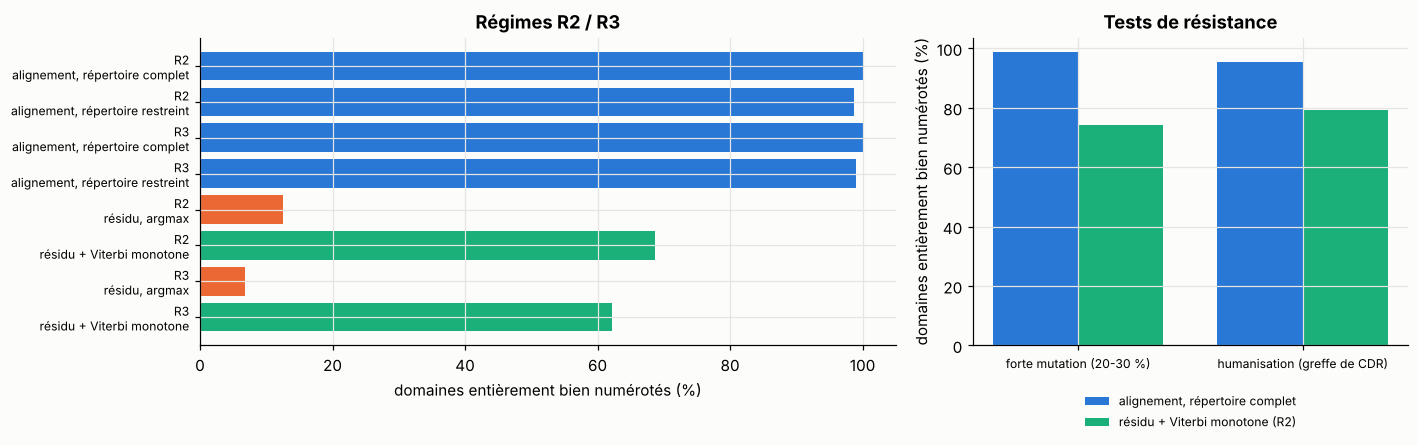

In [14]:
res_plot = pd.DataFrame(results).dropna(subset=["numbering"])
labels = [f"{r.split()[0]}\n{m}" for r, m in zip(res_plot.regime, res_plot.method)]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})
colors = [PALETTE[0] if "alignement" in m else PALETTE[2] if "Viterbi" in m else PALETTE[1] for m in res_plot.method]
axes[0].barh(range(len(res_plot)), res_plot.exact_domain * 100, color=colors)
axes[0].set_yticks(range(len(res_plot))); axes[0].set_yticklabels(labels, fontsize=8); axes[0].invert_yaxis()
axes[0].set_xlabel("domaines entièrement bien numérotés (%)"); axes[0].set_title("Régimes R2 / R3")
sr = pd.DataFrame(stress_rows)
x = np.arange(len(stress))
for k, method in enumerate(sr.method.unique()):
    vals = sr[sr.method == method].exact_domain * 100
    axes[1].bar(x + (k - 0.5) * 0.38, vals, 0.38, color=PALETTE[0] if "alignement" in method else PALETTE[2], label=method)
axes[1].set_xticks(x); axes[1].set_xticklabels(list(stress), fontsize=8); axes[1].set_ylabel("domaines entièrement bien numérotés (%)")
axes[1].legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.12)); axes[1].set_title("Tests de résistance")
plt.tight_layout(); plt.show()

Même sous forte mutation ou après greffe de CDR, l'alignement reste devant (environ 99 % et 95 % de domaines entièrement exacts, contre 74 % et 79 % pour le modèle par résidu) : les frameworks portent assez de signal pour l'alignement, et les règles IMGT font le reste.

## 7. Bilan : où un modèle appris peut gagner

Sur ces données synthétiques, les conclusions sont nettes, et elles orientent le projet :

1. **La numérotation et les régions d'un domaine V** sont très bien traitées par l'alignement + les règles IMGT, même quand la germline exacte manque. Un PLM ne fera guère mieux sur ces tâches pour des domaines standard ; il doit au minimum **égaler** l'alignement, et l'argument devient alors la **vitesse** (pas de recherche dans le répertoire, traitement par lots sur GPU) et la **robustesse** aux cas limites.
2. **L'identification (T4) quand la germline est absente** est le vrai point faible de l'alignement : il renvoie toujours une germline, avec assurance, même fausse. Un modèle appris peut prédire le **locus**, la **famille** et l'**espèce** à partir de propriétés plus générales, et surtout **s'abstenir** au niveau gène/allèle (prédiction sélective, calibration). C'est une contribution défendable.
3. **La délimitation des domaines dans des constructions** (T1) est naturelle pour un étiqueteur de séquence et pénible pour l'alignement (il faut balayer, gérer linkers, domaines C, peptides signaux, formats nouveaux).
4. **Le décodage contraint est non négociable** : il garantit des sorties valides et améliore l'exactitude gratuitement. Il faudra le garder avec le PLM.

> ⚠️ **Limites de ce notebook.** Les données sont synthétiques et sans insertions/délétions dans les frameworks ; les vraies séquences sont plus difficiles (indels, domaines atypiques, séquences partielles), et l'alignement réel (IMGT/DomainGapAlign) est bien plus sophistiqué que cette version. Refais exactement ces comparaisons sur les vraies données avant d'en tirer une conclusion pour l'article.

On sauvegarde les prédictions par domaine pour l'évaluation statistique du notebook 5.

In [15]:
records = []
for (r, method), rows in preds.items():
    for row in rows:
        records.append(dict(regime=r, method=method, **{k: v for k, v in row.items() if k != "pred_positions"}))
pd.DataFrame(records).to_csv(DATA / "baseline_predictions.csv", index=False)
t1.to_csv(DATA / "t1_predictions.csv", index=False)
pd.DataFrame(stress_rows).to_csv(DATA / "stress_results.csv", index=False)
print(len(records), "domain-level prediction rows saved")

2840 domain-level prediction rows saved


## 8. Récapitulatif

| Notion | À retenir |
|---|---|
| Référence | alignement sur germlines + ancres + règles de longueur des CDR |
| Répertoire | complet : numérotation et gène parfaits ici ; restreint : numérotation conservée, gène perdu |
| Modèle par résidu | scores locaux ; argmax souvent invalide |
| Viterbi monotone | positions strictement croissantes, $O(L \cdot S)$ par maximum préfixe |
| BIO | contraintes de transitions ; métrique sur les bornes des domaines |
| Où gagner | T4 avec abstention, espèces mal couvertes, constructions (T1), vitesse |

### 🏋️ Exercices

1. **BLOSUM62 et gaps affines.** Remplace le score simple par BLOSUM62 (Biopython) et des gaps affines. Le gène est-il mieux retrouvé à forte mutation ?
2. **Abstention de l'alignement.** Ajoute un seuil sur l'identité à la germline retenue en dessous duquel l'alignement répond « gène inconnu ». Trace la courbe couverture / exactitude du gène en R2 et en R3 (prédiction sélective).
3. **Contraintes plus riches.** Ajoute au Viterbi monotone une pénalité pour sauter une position **de framework** (les gaps sont rares en FR, fréquents au sommet des CDR). Mesure l'effet.
4. **Vraies données.** Sur 500 séquences réelles annotées par IMGT/DomainGapAlign, compare cette baseline à l'outil et liste les 10 premiers désaccords. Qui a raison ?

<details><summary>Indications</summary>

2. L'identité se calcule sur les paires alignées renvoyées par `overlap_align` ; la courbe montre à quel point le score d'alignement est un bon signal de confiance… ou non.
3. Ajoute à `prev_best` un terme dépendant de l'écart entre états ; la récurrence n'est alors plus un simple maximum préfixe, sauf si la pénalité est linéaire en nombre de positions sautées (astuce : ajouter $\lambda \cdot \text{rang}(s)$ aux scores).
</details>